In [11]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression

import os
os.chdir('E:/Machine_Learning/Cases/student_performance')

In [12]:
df = pd.read_csv('student_dataset_10000_rows.csv')
df.head()

,study_hours,attendance,sleep_hours,internet_usage,assignments_completed,previous_score,exam_score,placement_status
0,7,56,8,7,10,62,100.00,Placed
1,4,69,5,3,8,56,100.00,Placed
2,11,60,7,6,10,45,100.00,Placed
3,8,99,9,8,4,55,90.17,Placed
4,5,52,8,6,8,40,78.82,Placed


In [13]:
X,y = df.drop('placement_status',axis=1),df['placement_status']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)
lr = LogisticRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
accuracy_score(y_test,y_pred)

0.9993333333333333

### Kyphosis Dataset

In [14]:
kyph = pd.read_csv('E:/Machine_Learning/Cases/Kyphosis/Kyphosis.csv')
kyph

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15
...,...,...,...,...
76,present,157,3,13
77,absent,26,7,13
78,absent,120,2,13
79,present,42,7,6


In [15]:
X,y = kyph.drop('Kyphosis',axis=1),kyph['Kyphosis']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26)
lr = LogisticRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
acc = accuracy_score(y_test,y_pred)
acc

0.8

## Case study human-resources-analytics

In [19]:
from sklearn.pipeline import Pipeline
import os
os.chdir('E:/Machine_Learning/Cases/human-resources-analytics')
df = pd.read_csv('HR_comma_sep.csv')
df.head()

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.10,0.77,6,247,4,0,1,0,sales,low
3,0.92,0.85,5,259,5,0,1,0,sales,low
4,0.89,1.00,5,224,5,0,1,0,sales,low


In [26]:
X , y = df.drop('left',axis =1), df['left']
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

ohe = OneHotEncoder(sparse_output= False,drop='first')
ct = make_column_transformer((ohe,make_column_selector(dtype_include='object')),
                            ('passthrough',make_column_selector(dtype_include=['int64','float64'])),
                            verbose_feature_names_out=False)
ct =ct.set_output(transform = 'pandas')


In [27]:
lr = LogisticRegression()
pipe = Pipeline([('CT',ct),('LR',lr)])
pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)
acc = accuracy_score(y_test,y_pred)
acc

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8001778172927317

### {‘lbfgs’, ‘liblinear’, ‘newton-cg’, ‘newton-cholesky’, ‘sag’, ‘saga’}

In [41]:
solvers = ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
scores =[]
for s in solvers:
    lr = LogisticRegression(solver=s, max_iter=1000)
    pipe = Pipeline([('CT',ct),('LR',lr)])
    pipe.fit(X_train,y_train)
    y_pred = pipe.predict(X_test)
    acc= accuracy_score(y_test,y_pred)
    scores.append([s,acc])
data = pd.DataFrame(data = scores,columns=['solver','Accuracy'])
data.nlargest(1,columns='Accuracy')

C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\PGCP-AI.STUDENTSDC\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,solver,Accuracy
4,sag,0.793732


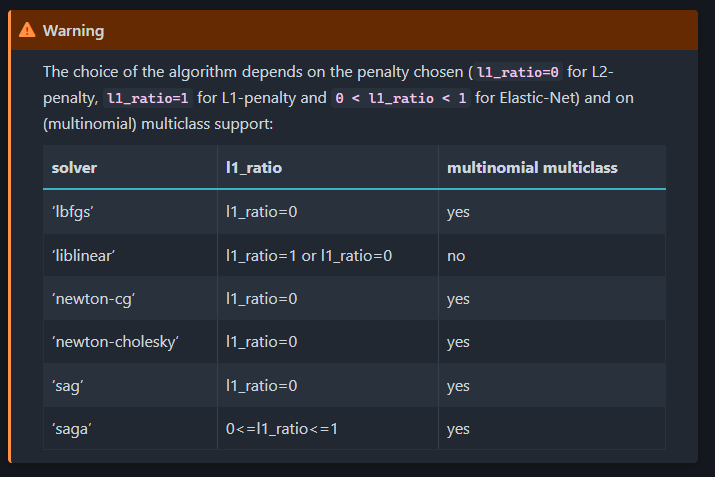

WE can use l1_ratio for fine tuning  according to this table's requirement .. l1_ratio =1 only 'linlinear' and 'saga' can be used

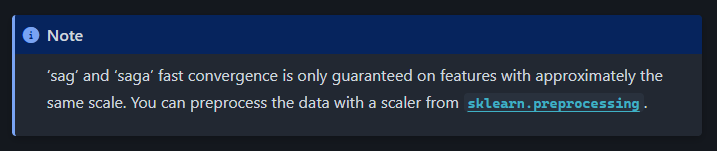